# Weinreb manuscript-v5 evidence and figure reproduction

This portable entry point verifies the bundled checkpoints, independently recalculates the recorded within-day pseudotime tests and Hallmark correction families, and recreates the two corrected branch-restricted manuscript displays from their exact cell tables. It does not refit the original reference partition, Palantir or cNMF. The unchanged executed scientific sources and their original builders are under `../current_source/`; the input and provenance documents explain the larger upstream files and original workspace dependencies.

Existing MacBook environment: Conda-compatible **chronoclone** at `/path/to/ChronoClone/.runtime/chronoclone`, kernel `chronoclone-paper`. Versions are printed below. On another machine use the repository environment specification; the notebook locates the checkout from its working directory and does not require the authors' home path. New figure files are written under `generated/weinreb/`, separate from the frozen manuscript figures.

MacBook execution from the checkout root: `/path/to/ChronoClone/.runtime/chronoclone/bin/jupyter-nbconvert --to notebook --execute --inplace --ExecutePreprocessor.kernel_name=chronoclone-paper analysis/weinreb/notebooks/01_v5_evidence_and_figures.ipynb`.

The plot cells retain the visible data shaping, complete figure construction, editable SVG save and display. Each creates one plot. Gene-program significance remains conditional on the original reference and observed clones; retained checks do not establish biological replication or causal effects.


In [1]:
from pathlib import Path
import json, hashlib, sys, platform, importlib.metadata as im
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.stats import kruskal
from statsmodels.stats.multitest import multipletests
from IPython.display import display
REPO=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'analysis/weinreb').is_dir())
STUDY=REPO/'analysis/weinreb'
PANELS=REPO/'generated/weinreb';TABLES=PANELS/'tables';REPORTS=PANELS/'reports'
for directory in [PANELS,TABLES,REPORTS]:directory.mkdir(parents=True,exist_ok=True)
environment={'environment':'chronoclone','MacBook_path':'/path/to/ChronoClone/.runtime/chronoclone','kernel':'chronoclone-paper','runtime_prefix':sys.prefix,'Python':platform.python_version(),'versions':{p:im.version(p) for p in ['numpy','pandas','matplotlib','scipy','statsmodels','nbformat','nbclient']}}
display(environment)
(REPORTS/'environment.json').write_text(json.dumps(environment,indent=2)+'\n')
mpl.rcParams.update({'font.family':'Arial','font.size':12.825,'axes.edgecolor':'#4B5563','axes.labelcolor':'#172033','axes.linewidth':.8,'xtick.color':'#4B5563','ytick.color':'#4B5563','text.color':'#172033','svg.fonttype':'none','pdf.fonttype':42,'figure.facecolor':'white','savefig.facecolor':'white'})
def sha(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for b in iter(lambda:f.read(1024*1024),b''):h.update(b)
    return h.hexdigest()
checks=[]


{'environment': 'chronoclone',
 'MacBook_path': '/path/to/ChronoClone/.runtime/chronoclone',
 'kernel': 'chronoclone-paper',
 'runtime_prefix': '/path/to/ChronoClone/.runtime/chronoclone',
 'Python': '3.11.15',
 'versions': {'numpy': '2.4.6',
  'pandas': '2.3.3',
  'matplotlib': '3.11.0',
  'scipy': '1.17.1',
  'statsmodels': '0.14.6',
  'nbformat': '5.10.4',
  'nbclient': '0.11.0'}}

## Verify immutable evidence files

In [2]:
mapping=json.loads((STUDY/'provenance/source_file_map.json').read_text())
verification=pd.DataFrame([{'path':r['path'],'bytes_match':(REPO/r['path']).stat().st_size==r['bytes'],'sha256_match':sha(REPO/r['path'])==r['sha256']} for r in mapping])
assert verification.bytes_match.all() and verification.sha256_match.all()
display(verification.agg({'bytes_match':['count','sum'],'sha256_match':['count','sum']}))
verification.to_csv(REPORTS/'input_verification.csv',index=False)
display(pd.read_json(STUDY/'provenance/source_notebook_execution.json')[['path','code_cells','executed_cells','saved_errors']])


,bytes_match,sha256_match
count,341,341
sum,341,341


,path,code_cells,executed_cells,saved_errors
0,analysis/weinreb/current_source/programs/0001_...,75,75,0
1,analysis/weinreb/current_source/ancestry/0001_...,22,22,0
2,analysis/weinreb/current_source/ancestry/0002_...,6,6,0
3,analysis/weinreb/current_source/dynamics/0001_...,13,13,0
4,analysis/weinreb/current_source/v3_display/000...,48,48,0
5,analysis/weinreb/current_source/v5_repair/0001...,5,5,0
6,analysis/weinreb/current_source/clone_embeddin...,5,5,0
7,analysis/weinreb/current_source/upstream/Figur...,40,35,0
8,analysis/weinreb/current_source/upstream/klein...,10,10,0
9,analysis/weinreb/current_source/upstream/0010_...,34,26,0


## Recalculate the complete within-day pseudotime test family

In [3]:
tests=pd.read_csv(STUDY/'tables/v5_repair/unchanged_q12_tests.csv')
saved_medians=pd.read_csv(STUDY/'tables/v3_display/pseudotime_omnibus_clone_medians.csv')
audit=[]
for row in tests.itertuples():
    block=saved_medians[(saved_medians.context==row.context)&(saved_medians.day==row.day)]
    included=[int(x.removeprefix('MC')) for x in row.metaclones_tested.split('|')]
    arrays=[block.loc[block.metaclone==mc,'pseudotime'].to_numpy(float) for mc in included]
    assert min(map(len,arrays))>=3
    test=kruskal(*arrays)
    audit.append({'context':row.context,'day':row.day,'H':test.statistic,'p':test.pvalue,'saved_H':row.kruskal_H,'saved_p':row.p_value,'saved_q':row.q_value})
audit=pd.DataFrame(audit);audit['q']=multipletests(audit.p,method='fdr_bh')[1]
assert len(audit)==12 and np.allclose(audit.H,audit.saved_H,rtol=1e-12,atol=0)
assert np.allclose(audit.p,audit.saved_p,rtol=1e-12,atol=0)
assert np.allclose(audit.q,audit.saved_q,rtol=1e-12,atol=0)
display(audit[['context','day','H','p','q']])
audit.to_csv(REPORTS/'q12_recalculation.csv',index=False)


,context,day,H,p,q
0,neutrophil_output,2,68.777711,4.111274e-14,8.222548e-14
1,neutrophil_output,4,83.130277,3.780453e-17,1.512181e-16
2,neutrophil_output,6,71.263620,2.289003e-15,6.867008e-15
3,monocyte_output,2,22.582287,4.934401e-05,5.921281e-05
4,monocyte_output,4,65.727544,3.505272e-14,8.222548e-14
5,monocyte_output,6,53.626474,2.265475e-12,3.883671e-12
6,multilineage_Baso,4,15.799934,1.246265e-03,1.359562e-03
7,multilineage_Baso,6,12.023502,7.303084e-03,7.303084e-03
8,multilineage_Neu,4,90.346186,1.111640e-18,6.669838e-18
9,multilineage_Neu,6,96.087108,6.691623e-20,8.029948e-19


## Preserve complete Hallmark families and molecular boundaries

In [4]:
effects=pd.read_csv(STUDY/'tables/ancestry/primary_program_effects.csv')
family_checks=[]
for tier,group in effects.groupby('tier',sort=False):
    calculated=multipletests(group.pvalue.to_numpy(float),method='fdr_bh')[1]
    error=float(np.max(np.abs(calculated-group.qvalue.to_numpy(float))))
    family_checks.append({'family':tier,'tests':len(group),'maximum_q_error':error})
    assert error<1e-12
display(pd.DataFrame(family_checks))
examples=pd.read_csv(STUDY/'tables/ancestry/evidence_review_selected_examples.csv')
joined=examples.merge(effects,on=['contrast_id','program'],suffixes=('_example','_full'),validate='one_to_one')
for value in ['effect_sd','qvalue','ci_low','ci_high']:
    assert np.allclose(joined[value+'_example'],joined[value+'_full'],rtol=0,atol=1e-12)
display(examples[['example_id','program','effect_sd','qvalue','source_fraction_effect','LOO_supported','LOO_same_direction']])
recovery=pd.read_csv(STUDY/'tables/programs/cnmf_postfreeze_program_recovery_summary.csv')
novelty=pd.read_csv(STUDY/'tables/programs/cnmf_metaclone_program_novelty_assessment.csv')
display(recovery.groupby('sensitivity').agg(programs=('program','nunique'),passing_complete_recovery=('recovery_supported','sum')))
display(novelty[['program','library_recovery_supported','source_balance_recovery_supported','novel_not_captured_candidate']])
pd.DataFrame(family_checks).to_csv(REPORTS/'hallmark_bh_families.csv',index=False)


,family,tests,maximum_q_error
0,within_lineage_ovr,950,3.999405e-15
1,within_lineage_pairwise,2000,3.695828e-15
2,monocyte_pace_50,50,2.480655e-16


,example_id,program,effect_sd,qvalue,source_fraction_effect,LOO_supported,LOO_same_direction
0,mono_1,Inflammatory Response,0.584366,0.002291,0.591816,7,7
1,mono_2,Myc Targets V2,0.551171,0.001083,0.531578,7,7
2,multi_divergence,Interferon Alpha Response,-0.818470,0.031454,0.084868,7,7
3,multi_convergence,Interferon Alpha Response,0.928651,0.004048,0.021021,7,7


,programs,passing_complete_recovery
sensitivity,,
leave_one_library_out,13,0
within_library_prog1_prog2_balance,13,3


,program,library_recovery_supported,source_balance_recovery_supported,novel_not_captured_candidate
0,Weinreb_D2_cNMF_K13_P01,False,False,False
1,Weinreb_D2_cNMF_K13_P02,False,False,False
2,Weinreb_D2_cNMF_K13_P03,False,False,False
3,Weinreb_D2_cNMF_K13_P04,False,False,False
4,Weinreb_D2_cNMF_K13_P05,False,False,False
5,Weinreb_D2_cNMF_K13_P06,False,False,False
6,Weinreb_D2_cNMF_K13_P07,False,True,False
7,Weinreb_D2_cNMF_K13_P08,False,True,False
8,Weinreb_D2_cNMF_K13_P09,False,False,False
9,Weinreb_D2_cNMF_K13_P10,False,True,False


## Corrected Figure 2E

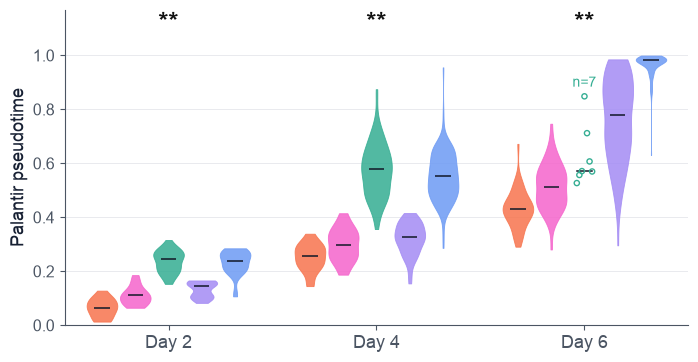

,metaclone,day,n_cells,n_clones,cell_median,branch
0,1,2,17,17,0.065091,Neu
1,1,4,32,16,0.257159,Neu
2,1,6,53,17,0.431609,Neu
3,9,2,44,24,0.245591,Neu
4,9,4,109,29,0.577277,Neu
5,9,6,7,2,0.571277,Neu
6,14,2,30,21,0.237761,Neu
7,14,4,147,26,0.551850,Neu
8,14,6,203,26,0.981149,Neu
9,16,2,16,13,0.147350,Neu


/path/to/ChronoClone/ChronoClone_paper/generated/weinreb/figure_2e_neutrophil_pseudotime.svg


In [5]:
STEM='figure_2e_neutrophil_pseudotime'; BRANCH='Neu'; CONTEXT='neutrophil_output'; MCS=[1, 22, 9, 16, 14]; DAYS=[2,4,6]
# Plot-specific data shaping, saved-summary equivalence and figure construction.
plot_data=pd.read_csv(STUDY/'tables/v5_repair'/(STEM+'_cells.csv'))
linked=set(pd.read_csv(STUDY/'tables/ancestry/ancestry_all_clone_day_linkage.csv').LARRY_ID.astype(str))
plot_data['LARRY_ID']=plot_data.LARRY_ID.astype(str)
colors=pd.read_csv(STUDY/'inputs/manuscript_metaclone_palette.csv').set_index('metaclone').color.to_dict()
assert plot_data.cell.is_unique and plot_data.LARRY_ID.isin(linked).all()
clone_medians=plot_data.groupby(['metaclone','day','LARRY_ID'],observed=True).pseudotime.median().reset_index()
comparison=clone_medians.merge(saved_medians[saved_medians.context==CONTEXT],on=['metaclone','day','LARRY_ID'],how='outer',suffixes=('_current','_saved'),indicator=True,validate='one_to_one')
assert comparison['_merge'].eq('both').all()
assert np.allclose(comparison.pseudotime_current,comparison.pseudotime_saved,rtol=0,atol=1e-14)
summary=plot_data.groupby(['metaclone','day'],observed=True).agg(n_cells=('cell','size'),n_clones=('LARRY_ID','nunique'),cell_median=('pseudotime','median')).reset_index()
summary['branch']=BRANCH
selected_tests=tests[tests.context==CONTEXT].set_index('day').loc[DAYS]
for day,row in selected_tests.iterrows():
    expected={int(k):v for k,v in json.loads(row.n_clones_by_metaclone).items()}
    actual=clone_medians[clone_medians.day==day].groupby('metaclone').size().to_dict()
    assert actual==expected
plot_data.to_csv(TABLES/(STEM+'_cells.csv'),index=False)
clone_medians.to_csv(TABLES/(STEM+'_clone_medians.csv'),index=False)
summary.to_csv(TABLES/(STEM+'_summary.csv'),index=False)
comparison.to_csv(TABLES/(STEM+'_saved_median_checks.csv'),index=False)
figure_count_before=len(plt.get_fignums())
fig,ax=plt.subplots(figsize=(7.34,4.21))
fig.subplots_adjust(left=.135,right=.985,bottom=.13,top=.88)
width=.80/len(MCS)
for day_index,day in enumerate(DAYS):
    for mc_index,mc in enumerate(MCS):
        values=plot_data.loc[(plot_data.day==day)&(plot_data.metaclone==mc),'pseudotime'].to_numpy(float)
        x=day_index+(mc_index-(len(MCS)-1)/2)*width
        if len(values)>=8 and np.unique(values).size>=2:
            violin=ax.violinplot([values],positions=[x],widths=width*.92,showmedians=True,showextrema=False)
            for body in violin['bodies']:
                body.set_facecolor(colors[mc]);body.set_edgecolor(colors[mc]);body.set_linewidth(.65);body.set_alpha(.86)
            violin['cmedians'].set_color('#111827');violin['cmedians'].set_linewidth(1.1)
        elif len(values):
            # Deterministic horizontal offsets reveal every sparse observation.
            point_x=np.linspace(x-width*.23,x+width*.23,len(values)) if len(values)>1 else np.array([x])
            ax.scatter(point_x,values,s=14,facecolors='none',edgecolors=colors[mc],linewidths=1.0,zorder=3)
            ax.plot([x-width*.23,x+width*.23],[np.median(values)]*2,color='#111827',lw=1.1)
            ax.text(x,float(np.max(values))+.025,f'n={len(values)}',ha='center',va='bottom',fontsize=10,color=colors[mc])
    ax.text(day_index,1.075,selected_tests.loc[day,'symbol'],ha='center',va='bottom',fontsize=18,fontweight='bold',color='#111111')
ax.set_xticks(range(3),[f'Day {day}' for day in DAYS],fontsize=12.825)
ax.set_ylabel('Palantir pseudotime',fontsize=12.825)
ax.set_ylim(0,1.17);ax.set_xlim(-.50,2.50)
ax.set_yticks(np.arange(0,1.01,.2));ax.tick_params(axis='y',labelsize=11.475)
ax.spines[['top','right']].set_visible(False)
ax.grid(axis='y',color='#E5E7EB',linewidth=.6);ax.set_axisbelow(True)
assert len(plt.get_fignums())==figure_count_before+1 and not ax.get_title()
fig.canvas.draw()
renderer=fig.canvas.get_renderer()
text_artists=[ax.yaxis.label,*ax.get_xticklabels(),*ax.get_yticklabels(),*ax.texts]
for artist in text_artists:
    box=artist.get_window_extent(renderer)
    assert box.x0>=0 and box.y0>=0 and box.x1<=fig.bbox.width and box.y1<=fig.bbox.height
fig.savefig(PANELS/(STEM+'.svg'),bbox_inches='tight',pad_inches=.06)
fig.savefig(PANELS/(STEM+'.png'),dpi=400,bbox_inches='tight',pad_inches=.06)
display(fig);plt.close(fig)
display(summary)
checks.append({'stem':STEM,'branch':BRANCH,'cells':len(plot_data),'clone_day_records':len(clone_medians),'saved_clone_medians_max_error':float(np.max(np.abs(comparison.pseudotime_current-comparison.pseudotime_saved))),'saved_test_membership_identical':True,'new_hypothesis_tests':0,'figure_count':1,'text_inside_frame':True,'svg_sha256':hashlib.sha256((PANELS/(STEM+'.svg')).read_bytes()).hexdigest(),'png_sha256':hashlib.sha256((PANELS/(STEM+'.png')).read_bytes()).hexdigest()})
print(PANELS/(STEM+'.svg'))


## Corrected Figure 2G

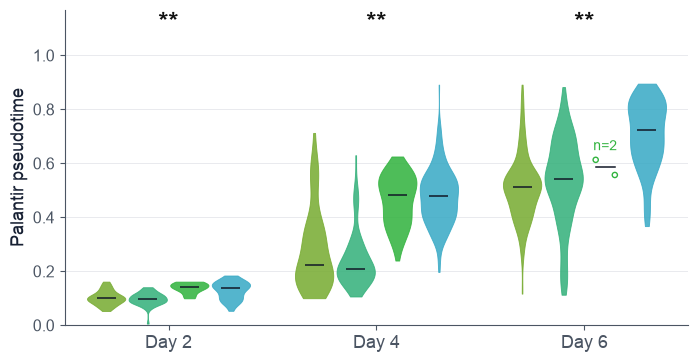

,metaclone,day,n_cells,n_clones,cell_median,branch
0,6,2,34,32,0.100400,Mono
1,6,4,76,24,0.223298,Mono
2,6,6,306,29,0.513010,Mono
3,7,2,11,9,0.142385,Mono
4,7,4,71,21,0.481547,Mono
5,7,6,2,2,0.585003,Mono
6,8,2,47,36,0.096629,Mono
7,8,4,97,31,0.210028,Mono
8,8,6,286,33,0.543209,Mono
9,12,2,29,23,0.138308,Mono


/path/to/ChronoClone/ChronoClone_paper/generated/weinreb/figure_2g_monocyte_cell_pseudotime.svg


In [6]:
STEM='figure_2g_monocyte_cell_pseudotime'; BRANCH='Mono'; CONTEXT='monocyte_output'; MCS=[6, 8, 7, 12]; DAYS=[2,4,6]
# Plot-specific data shaping, saved-summary equivalence and figure construction.
plot_data=pd.read_csv(STUDY/'tables/v5_repair'/(STEM+'_cells.csv'))
linked=set(pd.read_csv(STUDY/'tables/ancestry/ancestry_all_clone_day_linkage.csv').LARRY_ID.astype(str))
plot_data['LARRY_ID']=plot_data.LARRY_ID.astype(str)
colors=pd.read_csv(STUDY/'inputs/manuscript_metaclone_palette.csv').set_index('metaclone').color.to_dict()
assert plot_data.cell.is_unique and plot_data.LARRY_ID.isin(linked).all()
clone_medians=plot_data.groupby(['metaclone','day','LARRY_ID'],observed=True).pseudotime.median().reset_index()
comparison=clone_medians.merge(saved_medians[saved_medians.context==CONTEXT],on=['metaclone','day','LARRY_ID'],how='outer',suffixes=('_current','_saved'),indicator=True,validate='one_to_one')
assert comparison['_merge'].eq('both').all()
assert np.allclose(comparison.pseudotime_current,comparison.pseudotime_saved,rtol=0,atol=1e-14)
summary=plot_data.groupby(['metaclone','day'],observed=True).agg(n_cells=('cell','size'),n_clones=('LARRY_ID','nunique'),cell_median=('pseudotime','median')).reset_index()
summary['branch']=BRANCH
selected_tests=tests[tests.context==CONTEXT].set_index('day').loc[DAYS]
for day,row in selected_tests.iterrows():
    expected={int(k):v for k,v in json.loads(row.n_clones_by_metaclone).items()}
    actual=clone_medians[clone_medians.day==day].groupby('metaclone').size().to_dict()
    assert actual==expected
plot_data.to_csv(TABLES/(STEM+'_cells.csv'),index=False)
clone_medians.to_csv(TABLES/(STEM+'_clone_medians.csv'),index=False)
summary.to_csv(TABLES/(STEM+'_summary.csv'),index=False)
comparison.to_csv(TABLES/(STEM+'_saved_median_checks.csv'),index=False)
figure_count_before=len(plt.get_fignums())
fig,ax=plt.subplots(figsize=(7.34,4.21))
fig.subplots_adjust(left=.135,right=.985,bottom=.13,top=.88)
width=.80/len(MCS)
for day_index,day in enumerate(DAYS):
    for mc_index,mc in enumerate(MCS):
        values=plot_data.loc[(plot_data.day==day)&(plot_data.metaclone==mc),'pseudotime'].to_numpy(float)
        x=day_index+(mc_index-(len(MCS)-1)/2)*width
        if len(values)>=8 and np.unique(values).size>=2:
            violin=ax.violinplot([values],positions=[x],widths=width*.92,showmedians=True,showextrema=False)
            for body in violin['bodies']:
                body.set_facecolor(colors[mc]);body.set_edgecolor(colors[mc]);body.set_linewidth(.65);body.set_alpha(.86)
            violin['cmedians'].set_color('#111827');violin['cmedians'].set_linewidth(1.1)
        elif len(values):
            # Deterministic horizontal offsets reveal every sparse observation.
            point_x=np.linspace(x-width*.23,x+width*.23,len(values)) if len(values)>1 else np.array([x])
            ax.scatter(point_x,values,s=14,facecolors='none',edgecolors=colors[mc],linewidths=1.0,zorder=3)
            ax.plot([x-width*.23,x+width*.23],[np.median(values)]*2,color='#111827',lw=1.1)
            ax.text(x,float(np.max(values))+.025,f'n={len(values)}',ha='center',va='bottom',fontsize=10,color=colors[mc])
    ax.text(day_index,1.075,selected_tests.loc[day,'symbol'],ha='center',va='bottom',fontsize=18,fontweight='bold',color='#111111')
ax.set_xticks(range(3),[f'Day {day}' for day in DAYS],fontsize=12.825)
ax.set_ylabel('Palantir pseudotime',fontsize=12.825)
ax.set_ylim(0,1.17);ax.set_xlim(-.50,2.50)
ax.set_yticks(np.arange(0,1.01,.2));ax.tick_params(axis='y',labelsize=11.475)
ax.spines[['top','right']].set_visible(False)
ax.grid(axis='y',color='#E5E7EB',linewidth=.6);ax.set_axisbelow(True)
assert len(plt.get_fignums())==figure_count_before+1 and not ax.get_title()
fig.canvas.draw()
renderer=fig.canvas.get_renderer()
text_artists=[ax.yaxis.label,*ax.get_xticklabels(),*ax.get_yticklabels(),*ax.texts]
for artist in text_artists:
    box=artist.get_window_extent(renderer)
    assert box.x0>=0 and box.y0>=0 and box.x1<=fig.bbox.width and box.y1<=fig.bbox.height
fig.savefig(PANELS/(STEM+'.svg'),bbox_inches='tight',pad_inches=.06)
fig.savefig(PANELS/(STEM+'.png'),dpi=400,bbox_inches='tight',pad_inches=.06)
display(fig);plt.close(fig)
display(summary)
checks.append({'stem':STEM,'branch':BRANCH,'cells':len(plot_data),'clone_day_records':len(clone_medians),'saved_clone_medians_max_error':float(np.max(np.abs(comparison.pseudotime_current-comparison.pseudotime_saved))),'saved_test_membership_identical':True,'new_hypothesis_tests':0,'figure_count':1,'text_inside_frame':True,'svg_sha256':hashlib.sha256((PANELS/(STEM+'.svg')).read_bytes()).hexdigest(),'png_sha256':hashlib.sha256((PANELS/(STEM+'.png')).read_bytes()).hexdigest()})
print(PANELS/(STEM+'.svg'))


## Reproduction receipt

In [7]:
receipt=pd.DataFrame(checks)
assert len(receipt)==2 and receipt.saved_test_membership_identical.all()
figure_map=pd.read_csv(STUDY/'provenance/manuscript_figure_map.csv')
expected={Path(row.manuscript_asset).name:row.png_sha256 for row in figure_map.itertuples()}
receipt['manuscript_png_identical']=[row.png_sha256==expected[row.stem] for row in receipt.itertuples()]
assert receipt.manuscript_png_identical.all()
receipt.to_csv(REPORTS/'figure_reproduction.csv',index=False)
display(receipt[['stem','branch','cells','clone_day_records','saved_clone_medians_max_error','saved_test_membership_identical','figure_count','manuscript_png_identical']])
print('Preserved cell/clone cohorts and all original q12 test memberships match. Original partition, Palantir and cNMF fits were not rerun. Generated figures are separate from the manuscript authority.')


,stem,branch,cells,clone_day_records,saved_clone_medians_max_error,saved_test_membership_identical,figure_count,manuscript_png_identical
0,figure_2e_neutrophil_pseudotime,Neu,935,277,2.220446e-16,True,1,True
1,figure_2g_monocyte_cell_pseudotime,Mono,1357,322,1.110223e-16,True,1,True


Preserved cell/clone cohorts and all original q12 test memberships match. Original partition, Palantir and cNMF fits were not rerun. Generated figures are separate from the manuscript authority.
